In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Find dataset automatically
paths = [
    Path("Dataset/raw_hr_dataset.csv"),
    Path("../Dataset/raw_hr_dataset.csv")
]

file_path = next((p for p in paths if p.exists()), None)

if file_path is None:
    raise FileNotFoundError("Dataset file not found. Check folder location.")

# Load dataset
df = pd.read_csv(file_path)

# Display first 5 records
df.head()



,Employee_ID,Employee_Name,Gender,Age,Department,Job_Role,Designation,Education,Experience_Years,Joining_Date,...,Reason_for_Leaving,Job_Satisfaction,Work_Life_Balance,Absenteeism_Days,Leaves_Taken,Recruitment_Source,Hiring_Cost,Hiring_Date,Employee_Type,Engagement_Score
0,EMP-10001,Benjamin Davis,Male,25,Engineering,Software Engineer,Associate,PhD,3,2020-01-03,...,NaN,3,2,1,12,LinkedIn,5771.0,2019-12-12,Part-Time,40
1,EMP-10002,Justin Ramirez,Male,29,Marketing,Marketing Specialist,Senior,Bachelor's,2,2019-11-27,...,NaN,2,4,0,9,LinkedIn,3108.0,2019-10-30,Contract,52
2,EMP-10003,Edward Anderson,Male,24,Marketing,Marketing Manager,Senior,Bachelor's,3,2018-07-31,...,NaN,3,2,0,9,Campus Placement,1618.0,2018-06-20,Contract,55
3,EMP-10004,David Harris,Male,37,Finance,Financial Analyst,Manager,Bachelor's,11,2020-12-06,...,NaN,3,2,0,18,Referral,3881.0,2020-11-20,Full-Time,47
4,EMP-10005,Samantha Flores,Female,49,Marketing,Content Lead,Director,Bachelor's,18,2016-07-23,...,NaN,1,2,1,16,LinkedIn,6166.0,2016-07-07,Full-Time,40


In [7]:

# Dataset dimensions
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Data types and non-null counts
print("\nDataset Information:")
df.info()

# Statistical summary
df.describe()


Total Rows: 15000
Total Columns: 33

Column Names:
['Employee_ID', 'Employee_Name', 'Gender', 'Age', 'Department', 'Job_Role', 'Designation', 'Education', 'Experience_Years', 'Joining_Date', 'Exit_Date', 'Employment_Status', 'Manager', 'Location', 'Office', 'Work_Mode', 'Salary', 'Bonus', 'Overtime_Hours', 'Training_Hours', 'Performance_Rating', 'Promotion_Status', 'Attrition', 'Reason_for_Leaving', 'Job_Satisfaction', 'Work_Life_Balance', 'Absenteeism_Days', 'Leaves_Taken', 'Recruitment_Source', 'Hiring_Cost', 'Hiring_Date', 'Employee_Type', 'Engagement_Score']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 33 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Employee_ID         15000 non-null  object 
 1   Employee_Name       15000 non-null  object 
 2   Gender              15000 non-null  object 
 3   Age                 15000 non-null  int64  
 4   D

,Age,Experience_Years,Salary,Bonus,Overtime_Hours,Training_Hours,Performance_Rating,Job_Satisfaction,Work_Life_Balance,Absenteeism_Days,Leaves_Taken,Hiring_Cost,Engagement_Score
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.00000,15000.000000
mean,35.792333,8.370533,127472.126667,19074.813333,15.665733,34.797400,2.716267,2.891000,2.801067,2.234133,13.508533,4733.05520,57.865000
std,8.593051,6.152790,58486.691540,12013.613865,18.785162,11.893423,0.935354,1.079813,1.068567,2.957865,3.966246,3312.95121,14.305808
min,21.000000,0.000000,38000.000000,2000.000000,0.000000,8.000000,1.000000,1.000000,1.000000,0.000000,3.000000,1000.00000,40.000000
25%,30.000000,3.000000,80500.000000,10200.000000,3.000000,27.000000,2.000000,2.000000,2.000000,0.000000,11.000000,2409.00000,45.000000
50%,36.000000,8.000000,117600.000000,16100.000000,9.000000,35.000000,3.000000,3.000000,3.000000,1.000000,14.000000,3680.50000,56.000000
75%,42.000000,13.000000,159400.000000,25300.000000,21.000000,43.000000,3.000000,4.000000,4.000000,3.000000,16.000000,5899.00000,68.000000
max,64.000000,33.000000,374500.000000,88200.000000,140.000000,85.000000,5.000000,5.000000,5.000000,28.000000,30.000000,14993.00000,100.000000


In [8]:

# Missing values
print("Missing Values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

# Duplicate employee IDs
print("Duplicate Employee IDs:", df["Employee_ID"].duplicated().sum())


Missing Values:
Exit_Date             10351
Reason_for_Leaving    10351
dtype: int64

Duplicate Rows: 0
Duplicate Employee IDs: 0


In [9]:

# Create a copy of the original dataset
df_clean = df.copy()

# Remove duplicate records
df_clean = df_clean.drop_duplicates()

# Remove extra spaces from text columns
for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = df_clean[col].str.strip()

# Convert date columns
date_columns = ["Joining_Date", "Exit_Date", "Hiring_Date"]

for col in date_columns:
    df_clean[col] = pd.to_datetime(df_clean[col], errors="coerce")

# Check cleaned dataset
print("Cleaned Dataset Shape:", df_clean.shape)
print("\nDate Column Types:")
print(df_clean[date_columns].dtypes)


Cleaned Dataset Shape: (15000, 33)

Date Column Types:
Joining_Date    datetime64[ns]
Exit_Date       datetime64[ns]
Hiring_Date     datetime64[ns]
dtype: object


In [10]:

# Check employment status and attrition
print(pd.crosstab(df_clean["Employment_Status"], df_clean["Attrition"]))

# Check categorical values
for col in ["Gender", "Department", "Education", "Work_Mode", "Performance_Rating"]:
    print(f"\n{col}:")
    print(df_clean[col].value_counts())



Attrition             No   Yes
Employment_Status             
Active             10351     0
Resigned               0  3944
Terminated             0   705

Gender:
Gender
Male          7875
Female        6675
Non-Binary     450
Name: count, dtype: int64

Department:
Department
Engineering         4187
Sales               3014
Marketing           1788
Operations          1500
Finance             1494
Human Resources     1202
Product             1045
Customer Support     770
Name: count, dtype: int64

Education:
Education
Bachelor's          8298
Master's            4448
Associate Degree     907
PhD                  760
High School          587
Name: count, dtype: int64

Work_Mode:
Work_Mode
Hybrid    7481
Remote    4629
Onsite    2890
Name: count, dtype: int64

Performance_Rating:
Performance_Rating
3    5992
2    4755
4    2479
1    1382
5     392
Name: count, dtype: int64


In [11]:

# Export cleaned dataset
df_clean.to_csv("../Dataset/cleaned_hr_dataset.csv", index=False)

print("Cleaned dataset exported successfully!")


Cleaned dataset exported successfully!


In [12]:

# Descriptive statistical analysis
df_clean.describe().round(2)


,Age,Experience_Years,Joining_Date,Exit_Date,Salary,Bonus,Overtime_Hours,Training_Hours,Performance_Rating,Job_Satisfaction,Work_Life_Balance,Absenteeism_Days,Leaves_Taken,Hiring_Cost,Hiring_Date,Engagement_Score
count,15000.00,15000.00,15000,4649,15000.00,15000.00,15000.00,15000.00,15000.00,15000.00,15000.00,15000.00,15000.00,15000.00,15000,15000.00
mean,35.79,8.37,2020-10-03 16:37:43.680000,2023-09-15 11:01:36.795009792,127472.13,19074.81,15.67,34.80,2.72,2.89,2.80,2.23,13.51,4733.06,2020-09-04 03:04:53.759999744,57.86
min,21.00,0.00,2015-01-01 00:00:00,2015-06-05 00:00:00,38000.00,2000.00,0.00,8.00,1.00,1.00,1.00,0.00,3.00,1000.00,2014-11-17 00:00:00,40.00
25%,30.00,3.00,2017-11-21 18:00:00,2022-03-23 00:00:00,80500.00,10200.00,3.00,27.00,2.00,2.00,2.00,0.00,11.00,2409.00,2017-10-24 00:00:00,45.00
50%,36.00,8.00,2020-09-19 00:00:00,2024-05-28 00:00:00,117600.00,16100.00,9.00,35.00,3.00,3.00,3.00,1.00,14.00,3680.50,2020-08-21 00:00:00,56.00
75%,42.00,13.00,2023-08-22 00:00:00,2025-10-11 00:00:00,159400.00,25300.00,21.00,43.00,3.00,4.00,4.00,3.00,16.00,5899.00,2023-07-23 00:00:00,68.00
max,64.00,33.00,2026-06-30 00:00:00,2026-07-30 00:00:00,374500.00,88200.00,140.00,85.00,5.00,5.00,5.00,28.00,30.00,14993.00,2026-06-14 00:00:00,100.00
std,8.59,6.15,NaN,NaN,58486.69,12013.61,18.79,11.89,0.94,1.08,1.07,2.96,3.97,3312.95,NaN,14.31


In [13]:

# Department-wise employee and salary analysis
print("Department Analysis:")
display(df_clean.groupby("Department").agg(
    Total_Employees=("Employee_ID", "count"),
    Average_Salary=("Salary", "mean"),
    Average_Experience=("Experience_Years", "mean"),
    Average_Performance=("Performance_Rating", "mean")
).round(2))

# Education-wise salary analysis
print("\nEducation-wise Salary:")
display(df_clean.groupby("Education")["Salary"].mean().round(2))

# Work mode distribution
print("\nWork Mode Distribution:")
display(df_clean["Work_Mode"].value_counts())

# Gender distribution
print("\nGender Distribution:")
display(df_clean["Gender"].value_counts())


Department Analysis:


,Total_Employees,Average_Salary,Average_Experience,Average_Performance
Department,,,,
Customer Support,770,93040.52,8.41,2.69
Engineering,4187,150964.84,8.29,2.72
Finance,1494,133882.93,8.47,2.70
Human Resources,1202,105583.61,8.24,2.71
Marketing,1788,119572.04,8.31,2.73
Operations,1500,109918.00,8.41,2.73
Product,1045,150237.70,8.77,2.73
Sales,3014,114714.03,8.35,2.72



Education-wise Salary:


Education
Associate Degree    127580.60
Bachelor's          127651.80
High School         125172.23
Master's            127292.56
PhD                 128208.29
Name: Salary, dtype: float64


Work Mode Distribution:


Work_Mode
Hybrid    7481
Remote    4629
Onsite    2890
Name: count, dtype: int64


Gender Distribution:


Gender
Male          7875
Female        6675
Non-Binary     450
Name: count, dtype: int64

In [14]:

# Experience and salary relationship
print("Correlation:", 
      df_clean["Experience_Years"].corr(df_clean["Salary"]).round(3))


Correlation: 0.823


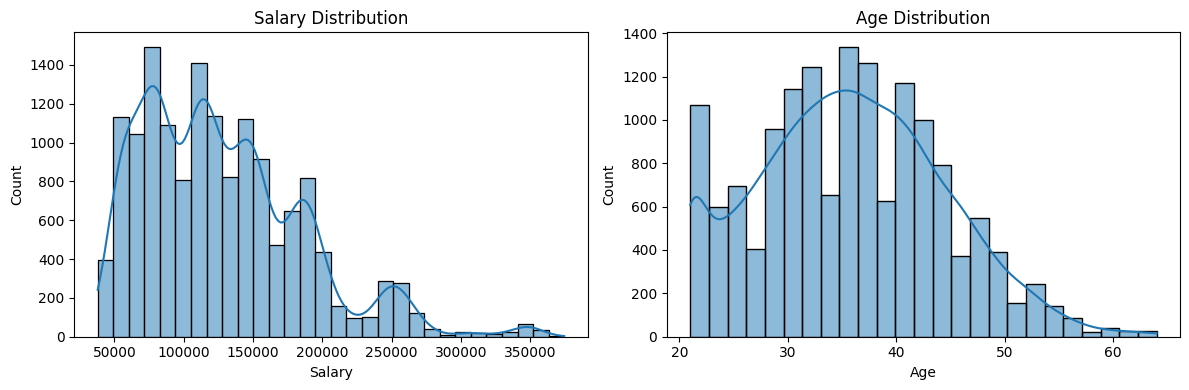

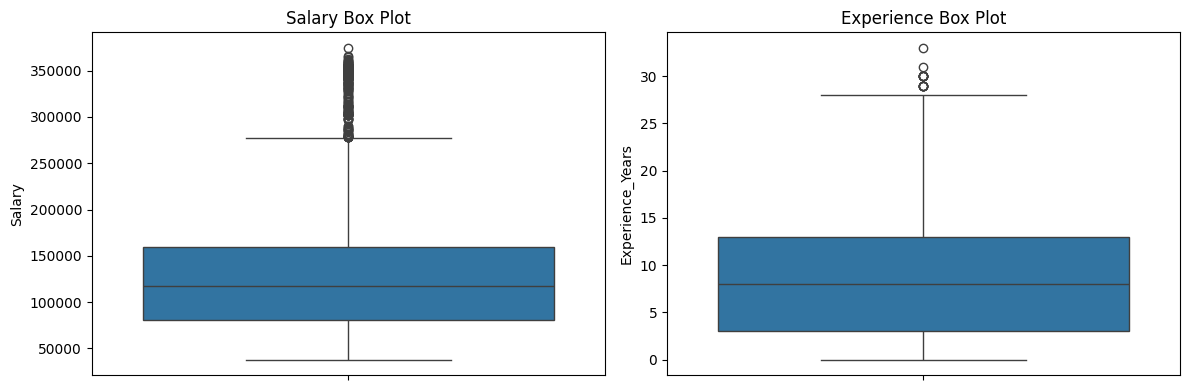

In [15]:

# Histograms
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df_clean["Salary"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Salary Distribution")

sns.histplot(df_clean["Age"], bins=25, kde=True, ax=axes[1])
axes[1].set_title("Age Distribution")

plt.tight_layout()
plt.show()


# Box plots
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(y=df_clean["Salary"], ax=axes[0])
axes[0].set_title("Salary Box Plot")

sns.boxplot(y=df_clean["Experience_Years"], ax=axes[1])
axes[1].set_title("Experience Box Plot")

plt.tight_layout()
plt.show()


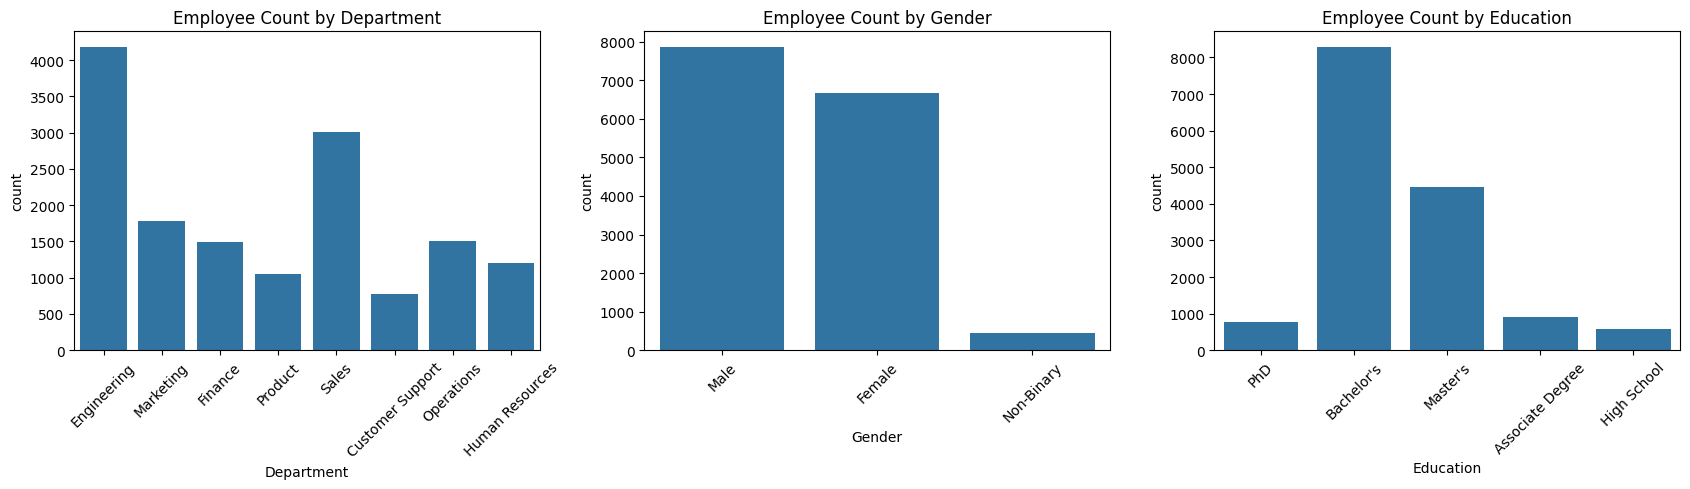

In [16]:

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, col in zip(axes, ["Department", "Gender", "Education"]):
    sns.countplot(data=df_clean, x=col, ax=ax)
    ax.set_title(f"Employee Count by {col}")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


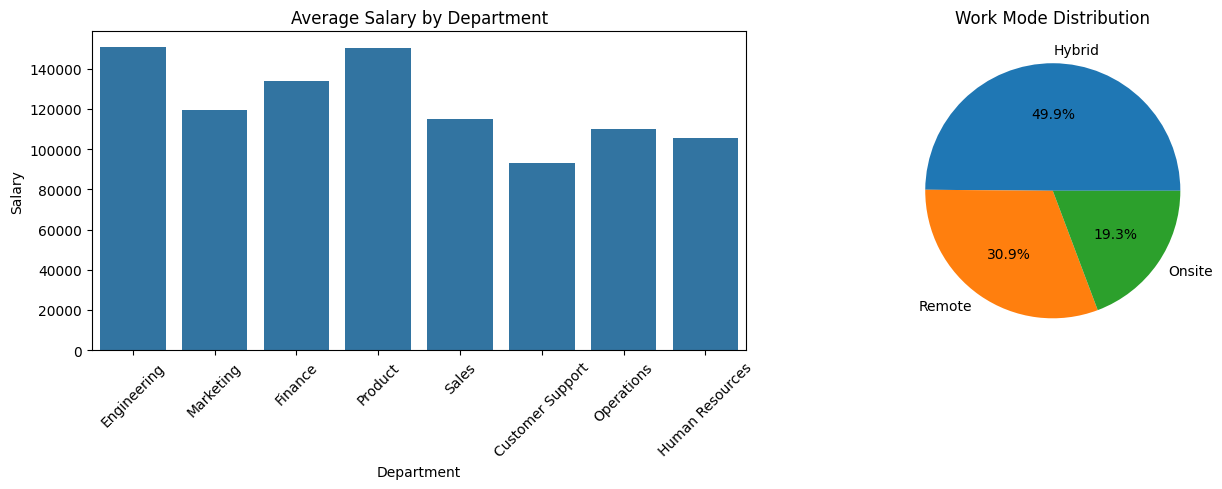

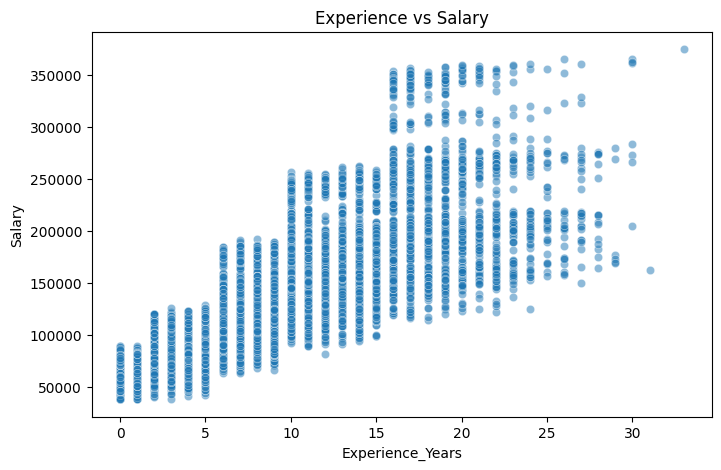

In [17]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Average salary by department
sns.barplot(data=df_clean, x="Department", y="Salary",
            estimator="mean", errorbar=None, ax=axes[0])
axes[0].set_title("Average Salary by Department")
axes[0].tick_params(axis="x", rotation=45)

# Work mode distribution
df_clean["Work_Mode"].value_counts().plot(
    kind="pie", autopct="%1.1f%%", ax=axes[1]
)
axes[1].set_title("Work Mode Distribution")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()


# Experience vs Salary
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_clean, x="Experience_Years", y="Salary", alpha=0.5)
plt.title("Experience vs Salary")
plt.show()


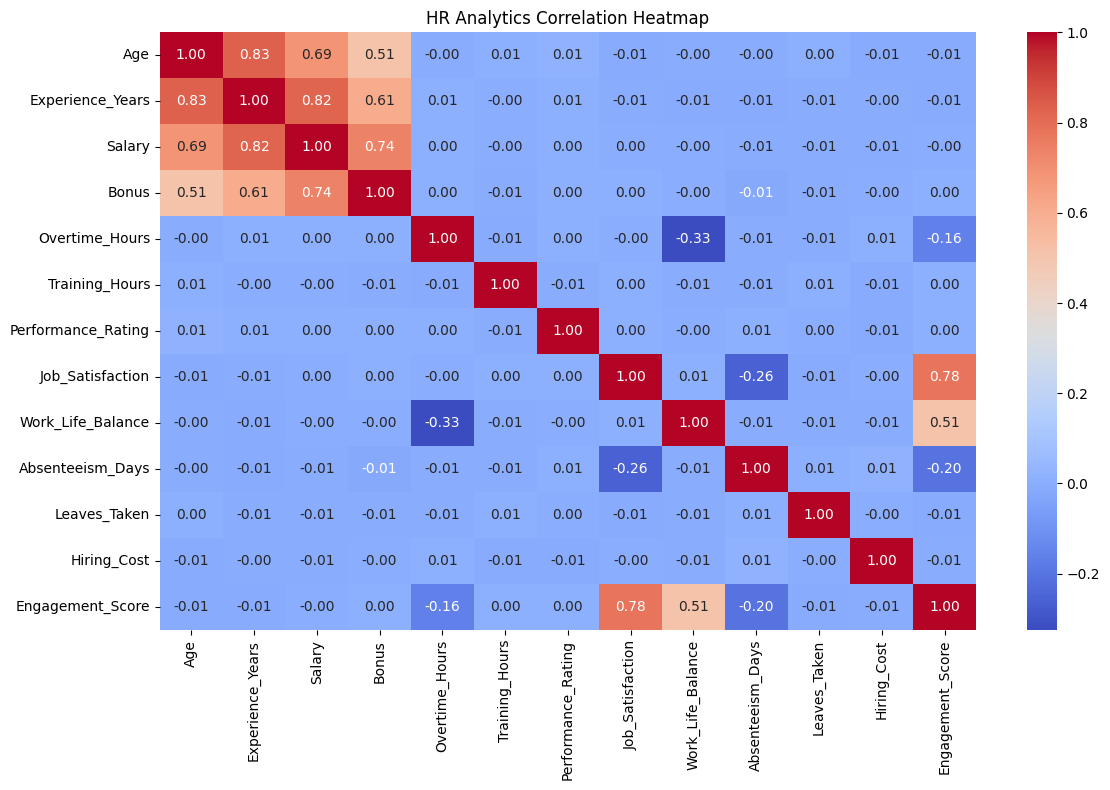

In [18]:

# Correlation between numerical variables
plt.figure(figsize=(12, 8))

sns.heatmap(
    df_clean.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("HR Analytics Correlation Heatmap")
plt.tight_layout()
plt.show()


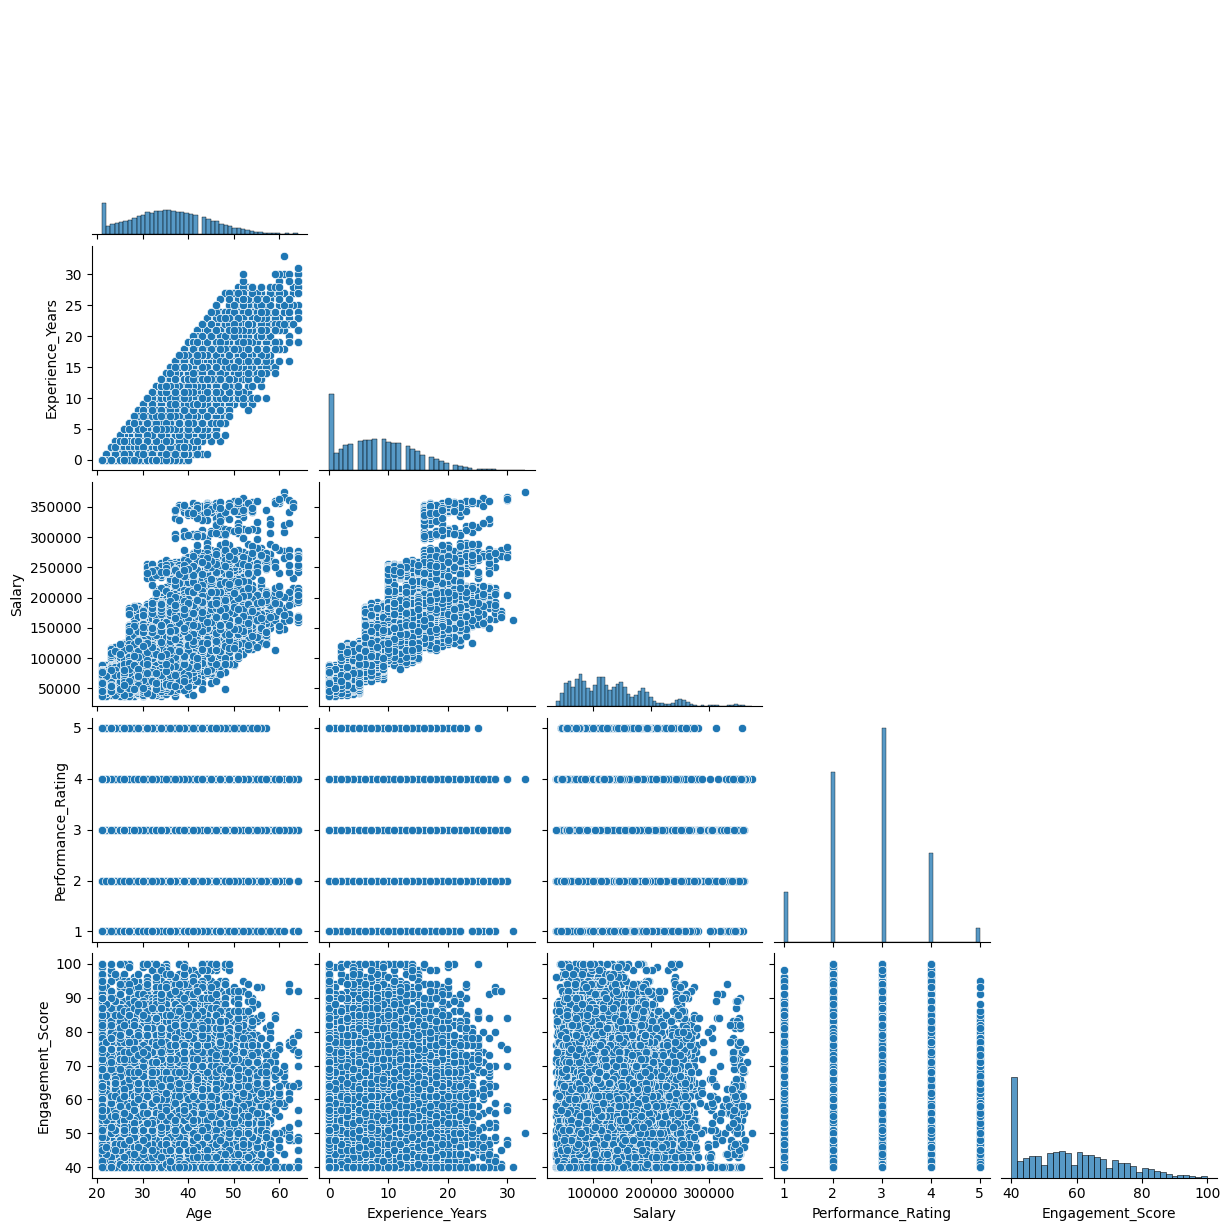

In [19]:

sns.pairplot(
    df_clean[[
        "Age",
        "Experience_Years",
        "Salary",
        "Performance_Rating",
        "Engagement_Score"
    ]],
    corner=True
)

plt.show()


In [20]:
# Key business insights
print("1. Highest Average Salary Department:")
print(df_clean.groupby("Department")["Salary"].mean().idxmax())

print("\n2. Lowest Average Salary Department:")
print(df_clean.groupby("Department")["Salary"].mean().idxmin())

print("\n3. Department with Most Employees:")
print(df_clean["Department"].value_counts().idxmax())

print("\n4. Most Common Work Mode:")
print(df_clean["Work_Mode"].value_counts().idxmax())

print("\n5. Gender Distribution:")
print(df_clean["Gender"].value_counts())

print("\n6. Attrition by Department:")
print(pd.crosstab(df_clean["Department"], df_clean["Attrition"]))

print("\n7. Average Salary by Education:")
print(df_clean.groupby("Education")["Salary"].mean().round(2))

print("\n8. Experience-Salary Correlation:")
print(df_clean["Experience_Years"].corr(df_clean["Salary"]).round(3))

1. Highest Average Salary Department:
Engineering

2. Lowest Average Salary Department:
Customer Support

3. Department with Most Employees:
Engineering

4. Most Common Work Mode:
Hybrid

5. Gender Distribution:
Gender
Male          7875
Female        6675
Non-Binary     450
Name: count, dtype: int64

6. Attrition by Department:
Attrition           No   Yes
Department                  
Customer Support   522   248
Engineering       2919  1268
Finance           1028   466
Human Resources    841   361
Marketing         1210   578
Operations        1052   448
Product            708   337
Sales             2071   943

7. Average Salary by Education:
Education
Associate Degree    127580.60
Bachelor's          127651.80
High School         125172.23
Master's            127292.56
PhD                 128208.29
Name: Salary, dtype: float64

8. Experience-Salary Correlation:
0.823


In [1]:
from pathlib import Path

report_dir = Path("../Reports")
report_dir.mkdir(parents=True, exist_ok=True)

print("Reports folder ready:", report_dir.resolve())

Reports folder ready: C:\Users\kruna\Desktop\HR-analytics\Reports


In [4]:
import pandas as pd

df_clean = pd.read_csv("../Dataset/cleaned_hr_dataset.csv")
from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import inch
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table,
    TableStyle, Image, PageBreak
)
import matplotlib.pyplot as plt
import seaborn as sns

pdf_path = report_dir / "HR_Analysis_Report.pdf"

doc = SimpleDocTemplate(
    str(pdf_path),
    pagesize=A4,
    rightMargin=40,
    leftMargin=40,
    topMargin=40,
    bottomMargin=40
)

styles = getSampleStyleSheet()
story = []

# Title
story.append(Paragraph("Employee Performance & HR Analytics", styles["Title"]))
story.append(Paragraph("Python Data Analysis Report", styles["Heading2"]))
story.append(Spacer(1, 15))

# Project overview
story.append(Paragraph("1. Project Overview", styles["Heading1"]))
story.append(Paragraph(
    "This project analyzes employee demographics, salaries, "
    "department performance, work arrangements, and attrition "
    "to identify workforce trends and support HR decision-making. "
    "The dataset used is synthetic.",
    styles["BodyText"]
))
story.append(Spacer(1, 12))

# Dataset summary
story.append(Paragraph("2. Dataset Summary", styles["Heading1"]))

summary_data = [
    ["Metric", "Value"],
    ["Total Employees", f"{len(df_clean):,}"],
    ["Total Columns", f"{df_clean.shape[1]}"],
    ["Active Employees", f"{(df_clean['Employment_Status'] == 'Active').sum():,}"],
    ["Employees Left", f"{(df_clean['Attrition'] == 'Yes').sum():,}"],
    ["Average Salary", f"{df_clean['Salary'].mean():,.2f}"],
    ["Average Experience", f"{df_clean['Experience_Years'].mean():.2f} years"],
    ["Attrition Rate", f"{(df_clean['Attrition'] == 'Yes').mean() * 100:.2f}%"]
]

table = Table(summary_data, colWidths=[220, 220])
table.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#243B53")),
    ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
    ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
    ("PADDING", (0, 0), (-1, -1), 7),
]))
story.append(table)
story.append(Spacer(1, 12))

# Data cleaning
story.append(Paragraph("3. Data Cleaning Summary", styles["Heading1"]))
cleaning_text = (
    "• Checked and removed duplicate records.<br/>"
    "• Removed leading and trailing spaces from text columns.<br/>"
    "• Converted Joining_Date, Exit_Date, and Hiring_Date to datetime format.<br/>"
    "• Preserved missing Exit_Date and Reason_for_Leaving values "
    "because they are expected for active employees.<br/>"
    "• Final cleaned dataset contains 15,000 rows and 33 columns."
)
story.append(Paragraph(cleaning_text, styles["BodyText"]))
story.append(Spacer(1, 12))

# Visualizations
story.append(Paragraph("4. Data Visualizations", styles["Heading1"]))

# Save charts temporarily in the Reports folder
chart1 = report_dir / "salary_distribution.png"
plt.figure(figsize=(7, 3.5))
sns.histplot(data=df_clean, x="Salary", bins=30, kde=True)
plt.title("Salary Distribution")
plt.tight_layout()
plt.savefig(chart1, dpi=150)
plt.close()
story.append(Image(str(chart1), width=6*inch, height=3*inch))

chart2 = report_dir / "department_salary.png"
dept_salary = df_clean.groupby("Department")["Salary"].mean().sort_values()
plt.figure(figsize=(7, 3.5))
dept_salary.plot(kind="bar")
plt.title("Average Salary by Department")
plt.ylabel("Average Salary")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(chart2, dpi=150)
plt.close()
story.append(Image(str(chart2), width=6*inch, height=3*inch))

chart3 = report_dir / "work_mode.png"
plt.figure(figsize=(6, 3.5))
df_clean["Work_Mode"].value_counts().plot(kind="pie", autopct="%1.1f%%")
plt.title("Work Mode Distribution")
plt.ylabel("")
plt.tight_layout()
plt.savefig(chart3, dpi=150)
plt.close()
story.append(Image(str(chart3), width=5*inch, height=3*inch))

story.append(Spacer(1, 12))

# Business insights
story.append(Paragraph("5. Business Insights", styles["Heading1"]))

insights = [
    "Engineering has the highest employee count and average salary.",
    "Customer Support has the lowest average salary.",
    "Hybrid is the most common work arrangement.",
    "Engineering has the highest number of employees who left.",
    "Marketing has the highest departmental attrition rate.",
    "Average salaries are relatively similar across education levels.",
    "Experience and salary have a strong positive correlation of 0.823."
]

for item in insights:
    story.append(Paragraph("• " + item, styles["BodyText"]))
    story.append(Spacer(1, 5))

# Conclusion
story.append(Paragraph("6. Conclusion", styles["Heading1"]))
story.append(Paragraph(
    "The analysis highlights differences in workforce size, salary, "
    "work arrangements, and employee attrition across departments. "
    "These findings can help HR teams identify areas for further "
    "investigation and improve workforce planning. Since the dataset "
    "is synthetic, the findings are illustrative rather than "
    "representative of a real organization.",
    styles["BodyText"]
))

doc.build(story)

print("PDF report generated successfully:", pdf_path.resolve())


PDF report generated successfully: C:\Users\kruna\Desktop\HR-analytics\Reports\HR_Analysis_Report.pdf


In [5]:
print("PDF exists:", pdf_path.exists())
print("PDF size:", round(pdf_path.stat().st_size / 1024, 2), "KB")

PDF exists: True
PDF size: 135.11 KB
